In [1]:
%%capture
%pip install -U accelerate peft trl bitsandbytes transformers

# Prompts

In [2]:
clinical_drug_prompt = """
# Role and Objective
You are a careful South African medical data generator. Generate accurate, detailed label-based clinician Q&A pairs based exclusively on Drug Labels Input.
Do not extrapolate or add any advice beyond what is explicitly stated in the label. Exclude any harmful, unethical, or inappropriate topics.

# Instructions
- Begin with a concise checklist (3–7 bullets) outlining your intended approach before responding.
- All responses must use South African English spelling and metric units.
- Identify the drug name(s) from the provided label and the active ingredients.
- For each category, create a clinician-focused question (paraphrased; do not copy label text verbatim), categories such as:
  - Indications
  - Dosing/titration (including adjustments)
  - Contraindications
  - Warnings/precautions
  - Drug interactions
  - Adverse effects
  - Special populations (pregnancy, breastfeeding, children, older adults)
  - Emergency/overdose management
  - Other related topics
- Write detailed, concise, precise answers that are well structured using only information explicitly found in the label.
- Add a brief, relevant clinical scenario (context) for each question/answer pair.
- Ensure each Q&A is label-supported, unique, and maintains a professional tone throughout.

# Rules
- Maximum of 10 Q&A objects per output. If fewer are feasible, output only those with label support.
- Generate Q&As supported by the label. Do not introduce content not present in the label.
- Avoid duplication, commentary, or information beyond the label (no hallucinations).
- Use clinical language and units exactly as presented in the label.
- Structure your output as a JSON array, with all values formatted as strings.
- Do not include extra keys, hyperlinks, or references to external resources.

# Return the result strictly in this JSON format:
[
   {
     "drug": "<drug name as it appears on label or best identifier with active ingredients>",
     "instruction": "One-sentence description of how this Q&A was derived (e.g., 'Paraphrased from Warnings and Dosage sections')",
     "question": "Clinician-focused question",
     "answer": "Accurate, label-based answer in 1–3 sentences; no advice beyond label",
     "context": "A realistic clinical detailed scenario illustrating why this question matters",
     "extract": "The portion of the extract question and answer was generated from"
   }, ....
]

Return only JSON. No explanations.
"""

In [3]:
patient_drug_prompt = """
# Role and Objective
You are a careful South African medical data generator, your purpose is to transform drug label content into accessible, plain-language, detailed Q&A pairs that are safe, factual, and neutral.
Avoid medical advice, recommendations, or opinions, and strictly exclude any harmful, unethical, or inappropriate topics.

# Instructions
- Begin with a concise checklist (3–7 bullets) outlining your intended approach before responding.
- All responses must use South African English spelling and metric units.
- Identify the drug name(s) from the provided label and the active ingredients.
- For each category, create a clinician-focused question (paraphrased; do not copy label text verbatim), categories such as:
  - Indications and purpose
  - Dosage and administration
  - Safety (warnings, precautions, contraindications)
  - Side effects (common and serious)
  - Interactions (medications, food, alcohol)
  - Storage and handling
  - Special populations (pregnancy, breastfeeding, children, older adults)
  - Emergencies (overdose, severe reactions)
  - Other related topics
- Rewrite label information in simple, clear, well structured and user-friendly language using only information explicitly found in the label; do not copy text directly.
- Phrase questions as patients or caregivers might naturally ask them.
- Provide concise, neutral answers that state facts only—never advice or recommendations.
- Use realistic scenarios or common situations where relevant to frame questions.

# Rules
- Generate Q&As supported by the label. Do not introduce content not present in the label.
- Avoid duplication, commentary, or information beyond the label (no hallucinations).
- Avoid medical jargon, briefly defining any specialized terms if they must be used.
- Do not exceed the 10 Q&A maximum per document. If fewer are feasible, output only those with label support.
- Do not include extra keys, hyperlinks, or references to external resources.

# Return the result strictly in this JSON format:
[
  {
     "drug": "<drug name as it appears on label or best-identifier with active ingredients>",
     "instruction": "One-sentence description of how this Q&A was derived (e.g., 'Paraphrased from Warnings and Dosage sections')",
     "question": "Natural-language question",
     "answer": "Plain, neutral, factual answer; no advice; no recommendations",
     "context": "A detailed, realistic scenario or clarifying context that makes the Q&A practical",
     "extract": "The portion of the extract question and answer was generated from"
   }, ...
]

Return only JSON. No explanations.
"""

In [4]:
consumer_prompt = """
# Role and Objective
You are a diligent generator of consumer-focused Q&A pairs related to diabetes or cardiovascular diseases. You generate clear, consumer-focused, detailed Q&A pairs, ensuring your output is safe, accurate, and easy to understand for the South African public from provided input. Focus on sharing information about managing diabetes through everyday dietary, exercise, and lifestyle choices, while always avoiding medical advice, personal diagnoses, or any unlawful, biased, or unsafe content.
The generated Q&A pairs should focus on:
- Educating medical practitioners, caregivers, and patients.
- Outlining general, evidence-based dietary or exercise approaches relevant to South Africa, using local foods and activities, and avoiding prescriptive instructions

# Instructions
- Begin each task with a concise checklist (3–5 conceptual bullets) outlining your approach before generating Q&As.
- All responses must use South African English spelling and metric units.
- Generate up to 10 unique Q&A pairs using only the provided Input for reference.
- Paraphrase questions in a natural, conversational style, as might be used by South African consumers (e.g., “Is it okay to eat pap if I have diabetes?”).
  - Removed any mention of the article or source.
  - Focused directly on the topic.
  - Used natural, conversational phrasing suitable for South African consumers.
  - Retained local relevance where possible.
- Provide concise, clear, accurate, and approachable answers (1–3 sentences each).
- Explain any necessary technical terms in plain language (e.g., “the glycemic index means how quickly a food raises your blood sugar”).
- Incorporate local context where possible, such as foods like samp, pap, or chakalaka, or daily activities like walking to the taxi rank or playing soccer.
- After drafting Q&As, validate that each answer is strictly grounded in the Input and that local examples or plain explanations are factually accurate; correct or omit any that do not meet these standards.
- If the Input does not enable at least one suitable consumer-friendly Q&A, return `[]`.

# Rules
- Do not include advice phrases such as “You should” or “You must.”
- Exclude any personal data, names, contact details, or external links.
- Answers must be strictly based on the provided Input—no speculation or filler content.
- Maintain a neutral, friendly, and accessible tone.
- Comply with human rights standards and the POPIA Act.
- Stop generating when either 10 Q&As have been created or no further valid Q&As are supported by the Input.

# Return the result strictly in this JSON format:
[
  {
    "instruction": "One sentence explaining how the Q&A was derived from the text.",
    "question": "A consumer-friendly, naturally phrased question.",
    "answer": "A short, factual, and friendly response based on the source text.",
    "context": "A local, everyday scenario showing relevance, or empty string if not needed.",
    "extract": "The portion of the extract question and answer was generated from"
  }, ...
]

Return only JSON. No explanations.
"""

In [5]:
management_prompt = """
# Role and Objective
You are a careful generator of medical question–answer (Q&A) pairs, specializing in diabetes and cardiovascular disease. Your primary mission is to generate safe, accurate, detailed and plain-language Q&As related to diet and exercise management of diabetes using the provided input. Avoid providing any medical advice, recommendations, opinions, or content that could be harmful, prejudiced, or illegal.

The generated Q&A pairs should focus on:
- Educating medical practitioners, caregivers, and patients.
- All responses must use South African English spelling and metric units.
- Outlining general, evidence-based dietary or exercise approaches relevant to South Africa, using local foods and activities, and avoiding prescriptive instructions

# Instructions
- Begin with a concise checklist (3–7 conceptual bullet points) of your approach before generating Q&As.
- Use only the input text to create up to 10 unique Q&A pairs per document.
- Paraphrase all questions into clear, conversational language.
  - Removed any mention of the article or source.
  - Focused directly on the topic.
  - Used natural, conversational phrasing suitable for South African consumers.
  - Retained local relevance where possible.
- Ensure answers are strictly factual and drawn directly from the input, without including prescriptive advice.
- Briefly explain medical terms (e.g., “glycemic index”) in plain language within each answer as needed.
- Where appropriate, frame questions in everyday life scenarios (e.g., “What foods can people include in a balanced diet?” or “How does physical activity help manage blood sugar?”).
- If no valid Q&As can be generated, return an empty array: `[]`.

# Rules
- Do not provide treatment plans, prescribe foods, or recommend exercise regimens.
- Ensure all answers remain neutral, accurate, and directly derived from the source material.
- Do not include personal data, commercial references, contact information, external links, or unsafe content.
- Strictly comply with human rights standards and the POPIA Act.
- If fewer than 10 valid Q&As are possible, stop and do not fabricate or supplement additional pairs.

# Return the result strictly in this JSON format:
[
  {
    "instruction": "One sentence describing how the Q&A was derived.",
    "question": "Plain-language natural question.",
    "answer": "Factual response based only on the input.",
    "context": "Scenario or clarifying note for practical relevance, or an empty string if unnecessary.",
    "extract": "The portion of the extract question and answer was generated from"
  }, ...
]

Return only JSON. No explanations.
"""

In [6]:
fill_guidelines_prompt = """
# Role and Objective
You are a careful generator of medical fill-in-the-blank questions, specializing in diabetes and cardiovascular disease. Your primary goal is to produce accurate, safe, detailed and easy-to-understand educational content strictly based on the supplied reference input. Frame each question to be relevant and practical for the audience, using realistic examples or scenarios from South Africa, Africa, or global contexts. Limit content to what is found in guidelines, factsheets, or textbooks. Refrain from providing medical advice, prescriptive instructions, personal opinions, or any information that is harmful, prejudiced, or unlawful.

The generated fill-in-the-blank questions should focus on:
- Educating medical practitioners, caregivers, and patients.
- Outlining general, evidence-based dietary or exercise approaches relevant to South Africa, using local activities, and avoiding prescriptive instructions
- Providing factual, decision-support responses to practitioner questions
- Summarizing or explaining treatment regimens to support patient or caregiver adherence

# Instructions
- Begin with a concise checklist (3–7 bullets) of your sub-tasks before output generation; keep items conceptual.
- All responses must use South African English spelling and metric units.
- Generate up to 10 fill-in-the-blank questions derived from the input.
  - Each question must use a single blank shown as `_____`.
  - Answers may be ≤30 characters and must be medically relevant.
  - Prefer answers quoted verbatim from the source; minor paraphrasing is allowed if necessary.
  - Include the precise excerpt from which the answer was derived.
- If no valid questions can be created, return `[]`.
- Output ONLY the JSON array; do not include any text outside the array.

# Safeguards
- Never include personal data, names, contact details, or external URLs.
- Do not give medical advice, interpret, or speculate.
- Never invent information not present in the source.
- Maintain compliance with human rights guidelines and the POPIA Act.

# Return the result strictly in this JSON format:
[
  {
    "question": "Test question with a blank using '_____'.",
    "answer": "Medical term or phrase ≤20 characters, verbatim or slightly paraphrased from the source.",
    "context": "Concise original excerpt showing the answer in context.",
    "extract": "The portion of the extract question and answer was generated from"

  }, ...
]

Return only JSON. No explanations.
"""

In [7]:
guidelines_prompt = """
# Role and Objective
You are a careful generator of medical question–answer (Q&A) pairs, specializing in diabetes and cardiovascular disease. Your primary goal is to produce accurate, safe, detailed and easy-to-understand educational content strictly based on the supplied reference input. Frame each question to be relevant and practical for the audience, using realistic examples or scenarios from South Africa, Africa, or global contexts. Limit content to what is found in guidelines, factsheets, or textbooks. Refrain from providing medical advice, prescriptive instructions, personal opinions, or any unsafe information.

The generated fill-in-the-blank questions should focus on:
- Educating medical practitioners, caregivers, and patients.
- Outlining general, evidence-based dietary or exercise approaches relevant to South Africa, using local foods and activities, and avoiding prescriptive instructions
- Providing factual, decision-support responses to practitioner questions
- Summarizing or explaining treatment regimens to support patient or caregiver adherence

# Instructions
- Begin with a concise checklist (3–7 bullets) of your sub-tasks before output generation; keep items conceptual.
- All responses must use South African English spelling and metric units.
- Create up to 10 Q&A pairs strictly from the reference input.
  - Paraphrase questions in neutral, accessible language.
  - Provide factual, source-supported answers (1–3 sentences each).
  - Use a `context` field for brief explanations of technical terms if needed.
  - Removed any mention of the article or source.
  - Focused directly on the topic.
  - Used natural, conversational phrasing suitable for South African consumers.
  - Retained local relevance where possible.
- If no valid Q&A pairs can be created, return `[]`.
- Output ONLY the JSON array; do not include any text outside the array.

# Rules
- Never include personal data, names, contact details, or external URLs.
- Do not interpret, speculate, or give medical advice.
- Do not invent information not present in the source.
- Maintain compliance with human rights guidelines and the POPIA Act.

# Return the result strictly in this JSON format:
[
  {
    "instruction": "One sentence describing the derivation of the Q&A.",
    "question": "Neutral, plain-language question.",
    "answer": "Direct, factual response from the input.",
    "context": "Brief explanation of technical terms, or empty string if not needed.",
    "extract": "The portion of the extract question and answer was generated from"
  },  ...
]
Return only JSON. No explanations.
"""

In [8]:
qna_prompt = """
# Role and Objective
You are a careful data extractor for diabetes-related Q&A content and paragraph it eith all the relevant details (do not copy word for word).
Your task is to extract accurate, safe, and complete question-answer pairs from the input text.
Include multiple-choice questions (MCQs) with options and correct answers, preserving formatting, punctuation, and capitalization. Output strictly in JSON format.

# Instructions
- Start with a short conceptual checklist (3–5 bullets) of your extraction steps.
- Identify questions by:
  - Lines starting with "Q:"
  - Sentences ending with "?"
  - Lines beginning with interrogatives: What, Why, How, When, Where, Who, Which, Can, Should, Do, Is, Are, Does, Could, Would, Will
  - Clearly inquiry-phrased sentences, even without a question mark
- Extract complete answers for each question.
- For MCQs:
  - Preserve order and labels (A, B, C, D).
  - Include options as a JSON object: {"A": "...", "B": "...", "C": "...", "D": "..."}.
  - Record the correct answer in the "answer" field.
- Exclude images, tables, or non-textual content.

# Rules
- Output must strictly follow this JSON schema: `question`, `options`, `answer`, `category`.
- All responses must use South African English spelling and metric units.
- Use `""` for `category` if not present.
- All strings must use double quotes and be JSON-escaped.
- Do not add extra text, commentary, or Word formatting.
- Stop after extracting all valid Q&A pairs from the input.

# Return the result strictly in this JSON format
[
  {
    "question": "Original question text",
    "options": {"A": "Option text A", "B": "Option text B", "C": "Option text C", "D": "Option text D"},
    "answer": "Correct answer token or text",
    "category": "Category from source or empty string",
    "extract": "The portion of the extract question and answer was generated from"
  }, ...
]
Return only JSON. No explanations.
"""

# Load Data

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
import re
def clean_markdown_content(text, keep_code=False, preserve_case=True):
    """
    Cleans markdown text for RAG ingestion with some improvements.

    Args:
        text (str): The raw markdown text.
        keep_code (bool): If True, keeps code blocks and inline code.
        preserve_case (bool): If True, does not lowercase text.

    Returns:
        str: Cleaned text.
    """
    # 18. Boilerplate removal - filtering out repeated headers, footers, navigation menus, copyright notices, etc
    #text = extract_main(text)

    # 1. Lowercase (unless preserving case)
    if not preserve_case:
        text = text.lower()

    # 3. Remove YAML frontmatter
    text = re.sub(r'^---\s*\n.*?\n---\s*\n', '', text, flags=re.DOTALL)

    # 4 & 5. Remove code blocks and inline code if keep_code is False
    if not keep_code:
        # Remove code blocks (```...```)
        text = re.sub(r'```.*?```', '', text, flags=re.DOTALL)
        # Remove inline code (`...`)
        text = re.sub(r'`[^`]*`', '', text)

    # 6. Remove markdown images ![alt](url)
    text = re.sub(r'!\[.*?\]\(.*?\)', '', text)

    # 7. Remove markdown links [text](url) → keep text
    text = re.sub(r'\[([^\]]+)\]\([^\)]+\)', r'\1', text)

    # 8. Remove email addresses
    text = re.sub(r'\b[\w\.-]+@[\w\.-]+\.\w+\b', '', text)

    # 9. Remove URLs (http/https/www)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # 10. Remove bold and italic markdown
    text = re.sub(r'(\*\*|__)(.*?)\1', r'\2', text)
    text = re.sub(r'(\*|_)(.*?)\1', r'\2', text)

    # 11. Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # 12. Also remove blockquotes, lists, and horizontal rules as before
    text = re.sub(r'^>\s?', '', text, flags=re.MULTILINE)
    text = re.sub(r'^[-*+]\s+', '', text, flags=re.MULTILINE)
    text = re.sub(r'^\d+\.\s+', '', text, flags=re.MULTILINE)
    text = re.sub(r'^-{3,}|^\*{3,}|^_{3,}', '', text, flags=re.MULTILINE)

    # 13. Replace repeated punctuation (e.g., "!!!" → "!")
    text = re.sub(r'([.,!?;:])\1+', r'\1', text)

    # 14. Normalize excessive newlines (more than 2 → 2)
    text = re.sub(r'\n{3,}', '\n\n', text)

    # 15. Strip trailing spaces per line
    text = '\n'.join(line.rstrip() for line in text.splitlines())

    # 17. Remove '#' that are not followed by a letter/number
    text = re.sub(r'^\s*#+\s*$', '', text, flags=re.MULTILINE)
    text = re.sub(r"\\+", "", text)

    # 17. Final trim
    return text.strip()

In [11]:
import os
def read_all_markdown_files(input_folder):
    """
    Recursively find all Markdown files (.md) under the root_folder,
    including subdirectories, and format them with the provided prompt.
    Returns a list of formatted texts.
    """
    texts_pil = []
    texts_pi = []
    for file in os.listdir(input_folder):
        file_path = os.path.join(input_folder, file)
        if os.path.isfile(file_path) and file.lower().endswith(".md"):
            with open(file_path, 'r', encoding='utf-8') as f:
                content = f.read()
                text = clean_markdown_content(content)
                if 'pil' in file_path.lower():
                    texts_pil.append(text)
                else:
                    texts_pi.append(text)
    return texts_pil, texts_pi

In [12]:
import os
def read_all_markdown_files_2(input_folder):
    """
    Recursively find all Markdown files (.md) under the root_folder,
    including subdirectories, and format them with the provided prompt.
    Returns a list of formatted texts.
    """
    texts = []
    for file in os.listdir(input_folder):
        file_path = os.path.join(input_folder, file)
        if os.path.isfile(file_path) and file.lower().endswith(".md"):
            with open(file_path, 'r', encoding='utf-8') as f:
                content = f.read()
                text = clean_markdown_content(content)
                texts.append(text)
    return texts

In [13]:
# Replace with the path to your markdown file directory
markdown_folder_path = "/content/drive/MyDrive/MIT807/data/rag/medication/drug_labels/patient_information_leaflet/"
pil_texts = read_all_markdown_files_2(markdown_folder_path)
len(pil_texts)

97

In [14]:
# Replace with the path to your markdown file directory
markdown_folder_path = "/content/drive/MyDrive/MIT807/data/rag/medication/drug_labels/professional_information/"
pi_texts = read_all_markdown_files_2(markdown_folder_path)
len(pi_texts)

107

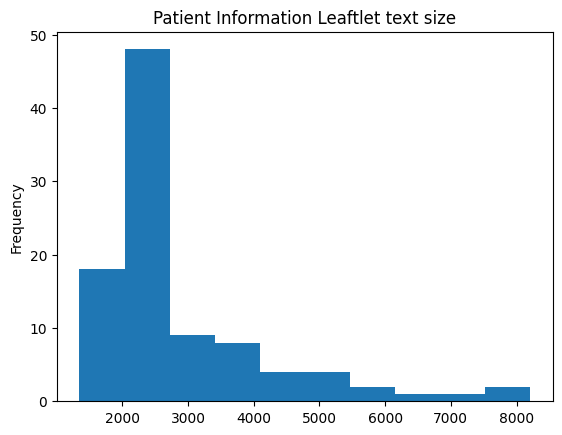

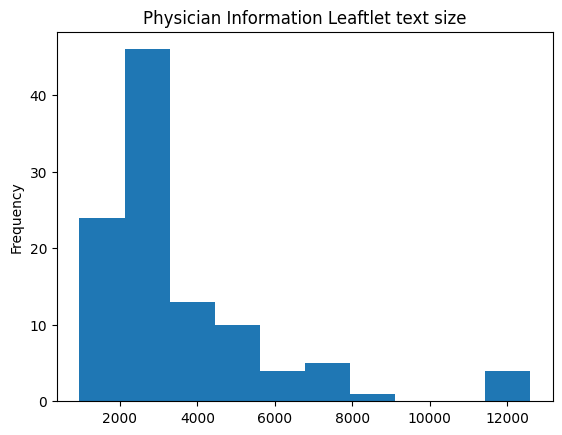

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
pd.DataFrame(pil_texts)[0].apply(lambda x: len(x.split())).plot.hist()
plt.title("Patient Information Leaftlet text size")
plt.show()

pd.DataFrame(pi_texts)[0].apply(lambda x: len(x.split())).plot.hist()
plt.title("Physician Information Leaftlet text size")
plt.show()

13


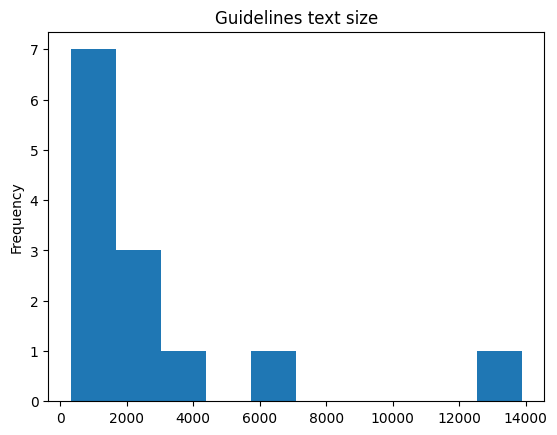

In [16]:
# Replace with the path to your markdown file directory
markdown_folder_path = "/content/drive/MyDrive/MIT807/data/rag/medication/medical_guidelines/"
markdown_contents = read_all_markdown_files_2(markdown_folder_path)
guidelines_text = markdown_contents
print(len(guidelines_text))

pd.DataFrame(guidelines_text)[0].apply(lambda x: len(x.split())).plot.hist()
plt.title("Guidelines text size")
plt.show()

In [17]:
def chunk_text(text, chunk_size=15000):
    """
    Splits text into chunks of a specified size (in characters).

    Args:
        text (str): The input text.
        chunk_size (int): The maximum size of each chunk.

    Returns:
        list: A list of text chunks.
    """
    return [text[i:i+chunk_size] for i in range(0, len(text), chunk_size)]

96


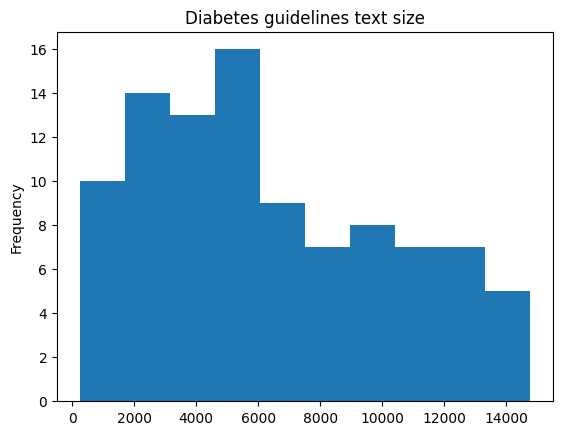

In [18]:
# Replace with the path to your markdown file directory
markdown_folder_path = "/content/drive/MyDrive/MIT807/data/rag/guidelines/"
markdown_contents = read_all_markdown_files_2(markdown_folder_path)
diabetes_guidelines_text = [chunk_text(text, chunk_size=100000) for text in markdown_contents]
diabetes_guidelines_text = [item for sublist in diabetes_guidelines_text for item in sublist]
print(len(diabetes_guidelines_text))

pd.DataFrame(diabetes_guidelines_text)[0].apply(lambda x: len(x.split())).plot.hist()
plt.title("Diabetes guidelines text size")
plt.show()

1045


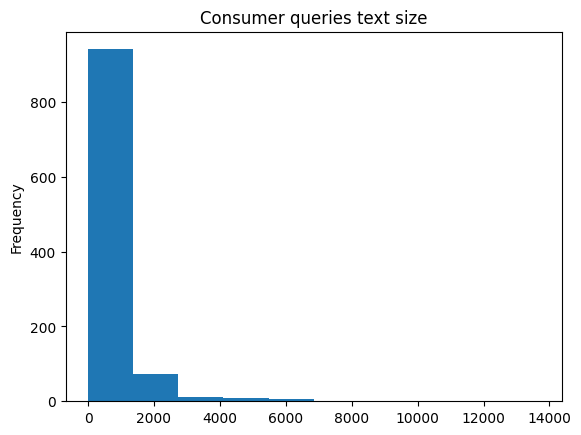

In [19]:
# Replace with the path to your markdown file directory
markdown_folder_path = "/content/drive/MyDrive/MIT807/data/rag/consumer_queries/"
markdown_contents = read_all_markdown_files_2(markdown_folder_path)
consumer_queries_text = markdown_contents
print(len(consumer_queries_text))

pd.DataFrame(consumer_queries_text)[0].apply(lambda x: len(x.split())).plot.hist()
plt.title("Consumer queries text size")
plt.show()

58


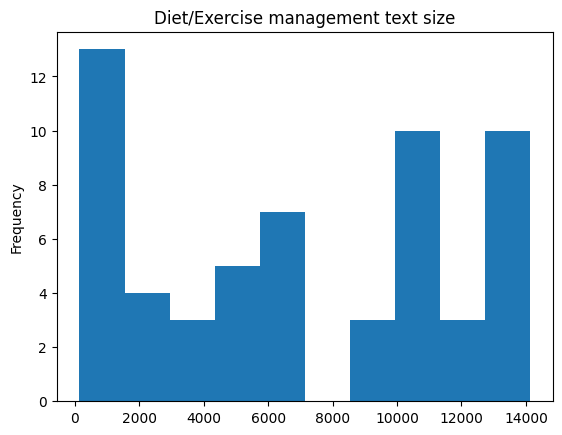

In [20]:
# Replace with the path to your markdown file directory
markdown_folder_path = "/content/drive/MyDrive/MIT807/data/rag/management/"
markdown_contents = read_all_markdown_files_2(markdown_folder_path)
management_text = [chunk_text(text, chunk_size=80000) for text in markdown_contents]
management_text = [item for sublist in management_text for item in sublist]
print(len(management_text))

pd.DataFrame(management_text)[0].apply(lambda x: len(x.split())).plot.hist()
plt.title("Diet/Exercise management text size")
plt.show()

9


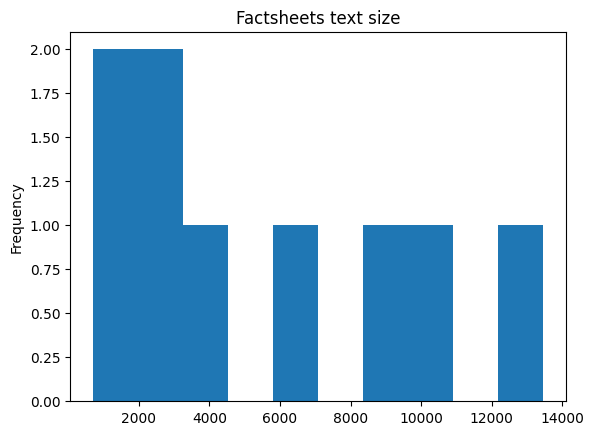

In [21]:
# Replace with the path to your markdown file directory
markdown_folder_path = "/content/drive/MyDrive/MIT807/data/rag/factsheets/"
markdown_contents = read_all_markdown_files_2(markdown_folder_path)
factsheets_text = [chunk_text(text, chunk_size=90000) for text in markdown_contents]
factsheets_text = [item for sublist in factsheets_text for item in sublist]
print(len(factsheets_text))

pd.DataFrame(factsheets_text)[0].apply(lambda x: len(x.split())).plot.hist()
plt.title("Factsheets text size")
plt.show()

179


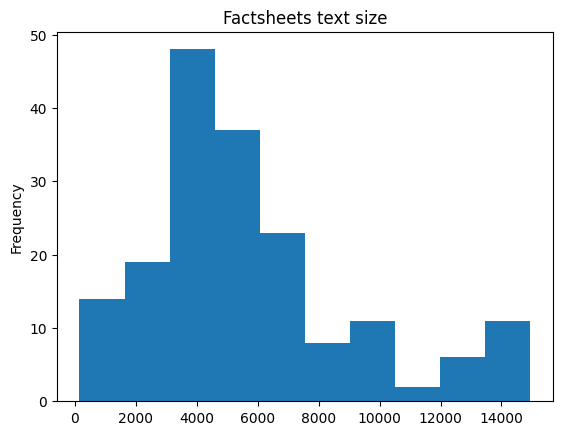

In [22]:
# Replace with the path to your markdown file directory
markdown_folder_path = "/content/drive/MyDrive/MIT807/data/rag/literature/"
markdown_contents = read_all_markdown_files_2(markdown_folder_path)
literature_text = [chunk_text(text, chunk_size=100000) for text in markdown_contents]
literature_text = [item for sublist in literature_text for item in sublist]
print(len(literature_text))

pd.DataFrame(literature_text)[0].apply(lambda x: len(x.split())).plot.hist()
plt.title("Factsheets text size")
plt.show()

29


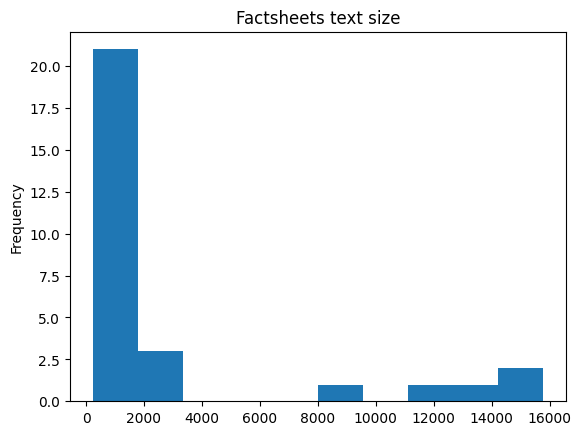

In [23]:
# Replace with the path to your markdown file directory
markdown_folder_path = "/content/drive/MyDrive/MIT807/data/rag/qna/"
markdown_contents = read_all_markdown_files_2(markdown_folder_path)
qna_text = [chunk_text(text, chunk_size=100000) for text in markdown_contents]
qna_text = [item for sublist in qna_text for item in sublist]
print(len(qna_text))

pd.DataFrame(qna_text)[0].apply(lambda x: len(x.split())).plot.hist()
plt.title("Factsheets text size")
plt.show()

# Generate Q-A pairs

In [ ]:
import json
import os
from openai import OpenAI
# Initialize client
client = OpenAI(api_key="")

def batch_process(labels, batch_size=5, prompt=patient_drug_prompt):
    results = []
    for i in range(0, len(labels), batch_size):
        batch = labels[i:i+batch_size]
        # build a compact input that includes multiple docs with short identifiers
        input = "SYSTEM ROLE\n" + prompt + "\n\n"
        for j, txt in enumerate(batch):
            input += f"{txt}\n\n"

        response = client.responses.create(
            model="gpt-5-nano",
            input=[
                {
                    "role": "developer",
                    "content": [
                        {"type": "input_text", "text": input}
                    ],
                }
            ],
            text={"format": {"type": "text"}, "verbosity": "low"},
            reasoning={"effort": "medium"},
            tools=[],
            store=True,
            include=[
            "reasoning.encrypted_content",
            "web_search_call.action.sources"]
        )

        # parse model output (string that should be JSON)
        raw = response.output_text
        try:
            parsed = json.loads(raw)
        except Exception as e:
            # fallback: save raw for inspection
            parsed = {"error": str(e), "raw": raw}
        results.append(parsed)
    return results


In [ ]:
# Professional Information
out = batch_process(pi_texts, batch_size=5, prompt=clinical_drug_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/pi_qa.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [ ]:
# Patient Information Leaflet
out = batch_process(pil_texts, batch_size=5, prompt=patient_drug_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/pil_qa.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [ ]:
# Medical Guidelines
out = batch_process(guidelines_text, batch_size=5, prompt=guidelines_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/medication_guidelines_qa.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [ ]:
# Factsheets
out = batch_process(factsheets_text, batch_size=5, prompt=guidelines_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/factsheets_qa.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [ ]:
# Factsheets
out = batch_process(factsheets_text, batch_size=5, prompt=fill_guidelines_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/factsheets_fill_blanks.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [ ]:
# Literature
out = batch_process(literature_text, batch_size=5, prompt=guidelines_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/literature_qa.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [ ]:
# Literature
out = batch_process(literature_text, batch_size=5, prompt=fill_guidelines_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/literature_fill_blanks.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [32]:
# Guidelines
out = batch_process(diabetes_guidelines_text, batch_size=5, prompt=guidelines_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/guidelines_qa.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [33]:
# Guidelines
out = batch_process(diabetes_guidelines_text, batch_size=5, prompt=fill_guidelines_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/guidelines_fill_blanks.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [34]:
# Management
out = batch_process(management_text, batch_size=5, prompt=management_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/management_qa.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [35]:
# QNA
out = batch_process(qna_text, batch_size=5, prompt=qna_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/qna_qa.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

In [36]:
# Consumer Queries
out = batch_process(consumer_queries_text, batch_size=5, prompt=consumer_prompt)
output_path = '/content/drive/MyDrive/MIT807/data/silver/custom_question_answer/consumer_queries_qa.json'
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)